# Visualizing Embedding Vectors

This is a companion notebook to a [Medium article](https://medium.com/@gallaghersam95/visualizing-embedding-vectors-99cac1d164c4).

How can we visualize high dimesional embedding vectors and see similarity and dissimilarity?



<Link>

This was created and written by [Sam Gallagher](https://www.linkedin.com/in/sam-gallagher-240166101/).

In [ ]:
# Install dependencies
%pip install numpy matplotlib sentence-transformers -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 171.5/171.5 kB 1.3 MB/s eta 0:00:00


In [1]:
# Load dependencies
import numpy as np
import matplotlib.pyplot as plt

## Process

Starting with a unit circle, let's wrap the points of the embedding vector equidistant around the circumference and shift them based on their values.

Let's say I have the following four-dimensional vector:

```
[0.3, 0.4, -0.5, 0.7]
```

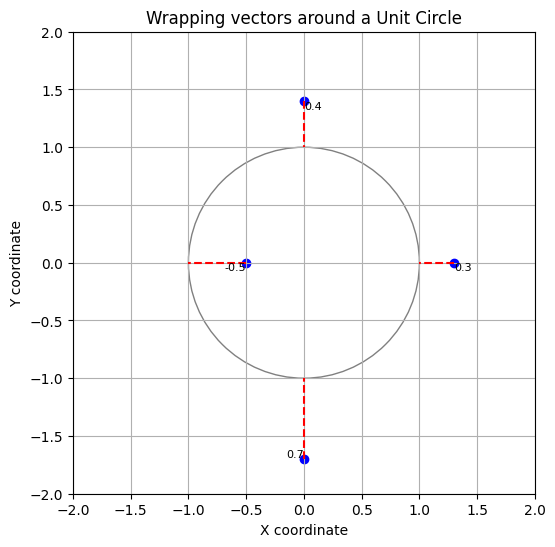

In [2]:
# Plotting the above example around a unit circle.
numbers = [0.3, 0.4, -0.5, 0.7]
N = len(numbers)

# Calculate the angles around the circle for N points
angles = np.linspace(0, 2 * np.pi, N, endpoint=False)

# Calculate the points in relation to the unit circle
radii = 1 + np.array(numbers)
x = radii * np.cos(angles)
y = radii * np.sin(angles)

# Calculate points on the circle so we can draw lines back to the circumference
circle_x = np.cos(angles)
circle_y = np.sin(angles)

# Plot the circle and points
plt.figure(figsize=(6, 6))
circle = plt.Circle((0, 0), 1, edgecolor='gray', facecolor='none')
ax = plt.gca()
ax.add_artist(circle)
ax.scatter(x, y, color='b')

# Draw lines from each vector point back to the circle
for px, py, cx, cy in zip(x, y, circle_x, circle_y):
  ax.plot([px, cx], [py, cy], 'red', linestyle='--')

# Add labels for the vector points
for i, (xi, yi) in enumerate(zip(x, y)):
  ax.text(xi, yi, f'{numbers[i]}', fontsize=8, ha='right' if xi < 0 else 'left', va='bottom' if yi < 0 else 'top')

# Set limits and aspect
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_aspect('equal')
ax.grid(True)

# Set Title
plt.title('Wrapping vectors around a Unit Circle')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.show()

In [3]:
# Generalizing the above into a convenience function

def plot_vectors(v1, v2, title, show_labels=False, normalize=False):
  # Normalize the data if required (along maximum)
  if normalize:
    max_value = max(max(v1), max(v2))
    v1 = [x / max_value for x in v1]
    v2 = [x / max_value for x in v2]

  # We must assume both vectors are the same length
  N = len(v1)
  angles = np.linspace(0, 2 * np.pi, N, endpoint=False)

  # Calculate the points in relation to the circle
  radii_1 = 1 + np.array(v1)
  x_1 = radii_1 * np.cos(angles)
  y_1 = radii_1 * np.sin(angles)

  radii_2 = 1 + np.array(v2)
  x_2 = radii_2 * np.cos(angles)
  y_2 = radii_2 * np.sin(angles)

  # Plot the circle and points
  plt.figure(figsize=(6, 6))
  circle = plt.Circle((0, 0), 1, edgecolor='gray', facecolor='none')
  ax = plt.gca()
  ax.add_artist(circle)
  ax.scatter(x_1, y_1, color='b') # Plotting v1
  ax.scatter(x_2, y_2, color='g') # Plotting v2

  # Draw lines between v1 and v2
  for px, py, tx, ty in zip(x_1, y_1, x_2, y_2):
    ax.plot([px, tx], [py, ty], 'red', linestyle='--')

  # Optionally write labels
  if show_labels:
    for i, (xi, yi) in enumerate(zip(x_1, y_1)):
      ax.text(xi, yi, f'{v1[i]}', fontsize=8, ha='right' if xi < 0 else 'left', va='bottom' if yi < 0 else 'top')
    for i, (xi, yi) in enumerate(zip(x_2, y_2)):
      ax.text(xi, yi, f'{v2[i]}', fontsize=8, ha='right' if xi < 0 else 'left', va='bottom' if yi < 0 else 'top')

  # Set limits and aspect
  ax.set_xlim(-2, 2)
  ax.set_ylim(-2, 2)
  ax.set_aspect('equal')
  ax.grid(True)

  # Set Title
  plt.title(title)
  plt.xlabel('X coordinate')
  plt.ylabel('Y coordinate')
  plt.show()

## Comparing Vectors

Now that we can plot a vector, let's compare two 10-dimensional vectors in the same way.

```
v1 = [-0.1, -0.8, 0.5, 0.1, -0.7,  0.3, 0.7, -0.5,  0.8, -0.4]
v2 = [ 0.3, -0.7, -0.2, 0.6, 0.8, -0.2, 0.6,  0.3, -0.4, -0.7]
```

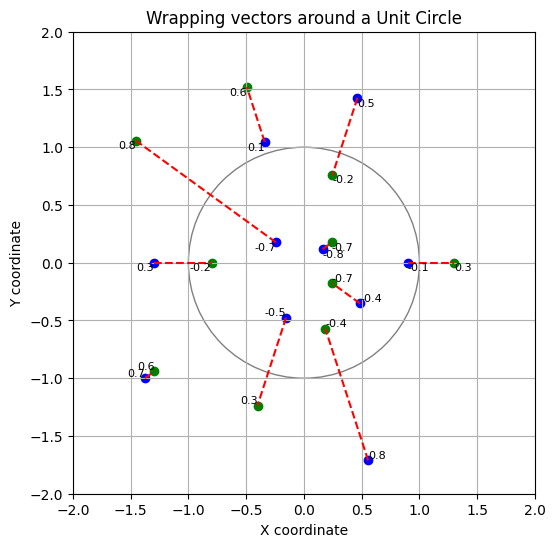

In [4]:
v1 = [-0.1, -0.8, 0.5, 0.1, -0.7,  0.3, 0.7, -0.5,  0.8, -0.4]
v2 = [ 0.3, -0.7, -0.2, 0.6, 0.8, -0.2, 0.6,  0.3, -0.4, -0.7]

plot_vectors(v1, v2, "Wrapping vectors around a Unit Circle", show_labels=True)

## Comparing Embedding Vectors

Now that we can compare two vectors of the same size, we can compare two embedding vectors.

This example will use sentence_transformers and all-MiniLM-L6-v2 but feel free to test with your favorite model instead.

Change the phrases to see how different embedding vectors compare against each other!

In [ ]:
# Load the model
from sentence_transformers import SentenceTransformer
model = SentenceTransformer("all-MiniLM-L6-v2")

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:88: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.7k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

1_Pooling/config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

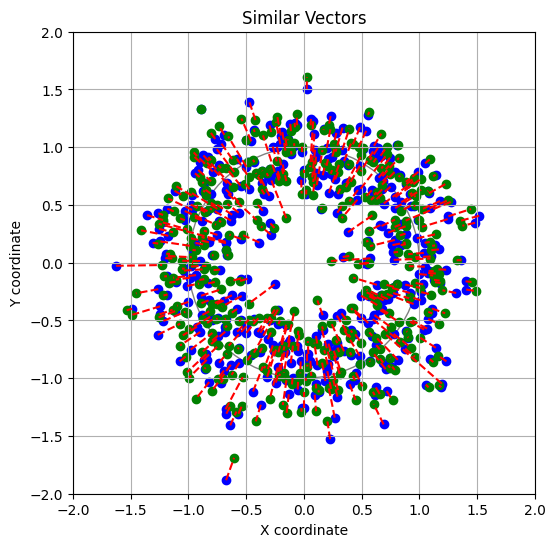

In [ ]:
# Build embedding vectors for two similar phrases
v1 = model.encode("Do you think we should have pasta or pizza for dinner?").tolist()
v2 = model.encode("I think we should order a pizza for dinner.").tolist()

# Plot the vectors
plot_vectors(v1, v2, "Similar Vectors", normalize=True)

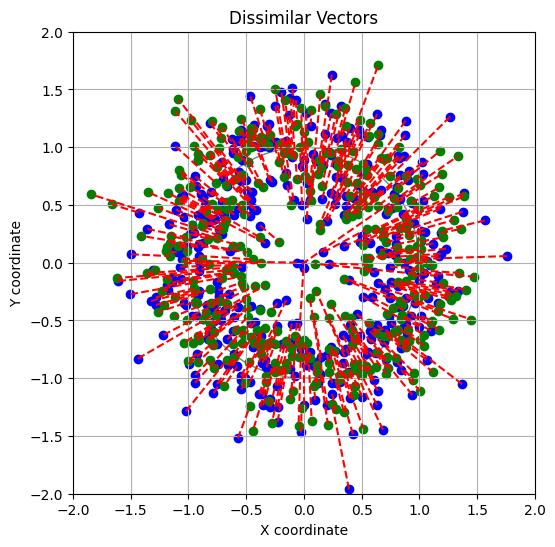

In [ ]:
# Build embedding vectors for two dissimilar phrases
v1 = model.encode("I hope the weather is nice today so I can go to the park later.").tolist()
v2 = model.encode("Working in higher dimensions of math can seem a bit intimidating.").tolist()

# Plot the vectors
plot_vectors(v1, v2, "Dissimilar Vectors", normalize=True)

## The End

Hope that was fun. Let me know if you have any questions of interesting use cases for visuals like this.

## Mine

In [37]:
import os
import torch

In [38]:
CONCEPT_PATH = '../../exp/asso_opt/CUB/CUB_allshot_fac'
CONCEPT_BL1_PATH = '../../exp/asso_opt/CUB/CUB_allshot_fac_bl1'
CONCEPT_BL2_PATH = '../../exp/asso_opt/CUB/CUB_allshot_fac_bl2'
CONCEPT_BL3_PATH = '../../exp/asso_opt/CUB/CUB_allshot_fac_bl3'
CONCEPT_BL4_PATH = '../../exp/asso_opt/CUB/CUB_allshot_fac_bl4'

In [39]:
concept_feats = torch.load(os.path.join(CONCEPT_PATH, 'concepts_feat_ViT-L-14.pth'))
concept_feats_bl1 = torch.load(os.path.join(CONCEPT_BL1_PATH, 'concepts_feat_ViT-L-14.pth'))
concept_feats_bl2 = torch.load(os.path.join(CONCEPT_BL2_PATH, 'concepts_feat_ViT-L-14.pth'))
concept_feats_bl3 = torch.load(os.path.join(CONCEPT_BL3_PATH, 'concepts_feat_ViT-L-14.pth'))
concept_feats_bl4 = torch.load(os.path.join(CONCEPT_BL4_PATH, 'concepts_feat_ViT-L-14.pth'))

In [40]:
print(concept_feats.shape)
print(concept_feats_bl1.shape)
print(concept_feats_bl2.shape)
print(concept_feats_bl3.shape)
print(concept_feats_bl4.shape)

torch.Size([45574, 768])
torch.Size([200, 768])
torch.Size([1, 768])
torch.Size([2000, 768])
torch.Size([4000, 768])


In [50]:
concept_raws = np.load(os.path.join(CONCEPT_PATH, 'concepts_raw_selected.npy'))
concept_raws_bl1 = np.load(os.path.join(CONCEPT_BL1_PATH, 'concepts_raw_selected.npy'))
concept_raws_bl2 = np.load(os.path.join(CONCEPT_BL2_PATH, 'concepts_raw_selected.npy'))
concept_raws_bl3 = np.load(os.path.join(CONCEPT_BL3_PATH, 'concepts_raw_selected.npy'))
concept_raws_bl4 = np.load(os.path.join(CONCEPT_BL4_PATH, 'concepts_raw_selected.npy'))

print(concept_raws.shape)
print(concept_raws_bl1.shape)
print(concept_raws_bl2.shape)
print(concept_raws_bl3.shape)
print(concept_raws_bl4.shape)

print(concept_raws[0])
print(concept_raws_bl1[0])
print(concept_raws_bl2[0])
print(concept_raws_bl3[0])
print(concept_raws_bl4[0])

(45574,)
(200,)
(1,)
(2000,)
(4000,)
"a rich, musical warble"
acadian flycatcher

pseudo concept 1
pseudo concept 1


In [73]:
concept_raws = np.load(os.path.join(CONCEPT_PATH, 'concepts_raw_selected.npy'))
concept_raws_bl1 = np.load(os.path.join(CONCEPT_BL1_PATH, 'concepts_raw_selected.npy'))
concept_raws_bl2 = np.load(os.path.join(CONCEPT_BL2_PATH, 'concepts_raw_selected.npy'))
concept_raws_bl3 = np.load(os.path.join(CONCEPT_BL3_PATH, 'concepts_raw_selected.npy'))
concept_raws_bl4 = np.load(os.path.join(CONCEPT_BL4_PATH, 'concepts_raw_selected.npy'))

print(concept_raws.shape)
print(concept_raws_bl1.shape)
print(concept_raws_bl2.shape)
print(concept_raws_bl3.shape)
print(concept_raws_bl4.shape)

print(concept_raws[0])
print(concept_raws_bl1[0])
print(concept_raws_bl2[0])
print(concept_raws_bl3[0])
print(concept_raws_bl4[0])

(45574,)
(200,)
(1,)
(2000,)
(4000,)
"a rich, musical warble"
acadian flycatcher

pseudo concept 1
pseudo concept 1


In [55]:
ORI_CONCEPT_PATH = '../../datasets/CUB/concepts'
ORI_CONCEPT_BL1_PATH = '../../datasets/CUB/concepts_bl1'
ORI_CONCEPT_BL2_PATH = '../../datasets/CUB/concepts_bl2'
ORI_CONCEPT_BL3_PATH = '../../datasets/CUB/concepts_bl3'
ORI_CONCEPT_BL4_PATH = '../../datasets/CUB/concepts_bl4'

In [56]:
ori_concept_raws = np.load(os.path.join(ORI_CONCEPT_PATH, 'concepts_raw.npy'))
ori_concept_raws_bl1 = np.load(os.path.join(ORI_CONCEPT_BL1_PATH, 'concepts_raw.npy'))
ori_concept_raws_bl2 = np.load(os.path.join(ORI_CONCEPT_BL2_PATH, 'concepts_raw.npy'))
ori_concept_raws_bl3 = np.load(os.path.join(ORI_CONCEPT_BL3_PATH, 'concepts_raw.npy'))
ori_concept_raws_bl4 = np.load(os.path.join(ORI_CONCEPT_BL4_PATH, 'concepts_raw.npy'))

print(ori_concept_raws.shape)
print(ori_concept_raws_bl1.shape)
print(ori_concept_raws_bl2.shape)
print(ori_concept_raws_bl3.shape)
print(ori_concept_raws_bl4.shape)

print(ori_concept_raws[0])
print(ori_concept_raws_bl1[0])
print(ori_concept_raws_bl2[0])
print(ori_concept_raws_bl3[0])
print(ori_concept_raws_bl4[0])

(91452,)
(200,)
(200,)
(2000,)
(4000,)
can often be seen riding the waves
acadian flycatcher

pseudo concept 1
pseudo concept 1


In [92]:
index1 = 100
index2 = 200
emb_vec_1 = concept_feats[index1]
emb_vec_2 = concept_feats[index2]
print(emb_vec_1.shape)
print(emb_vec_2.shape)

torch.Size([768])
torch.Size([768])


16-20 inches in length
3 to 5 eggs in a nest made of leaves, grass, and other plant material


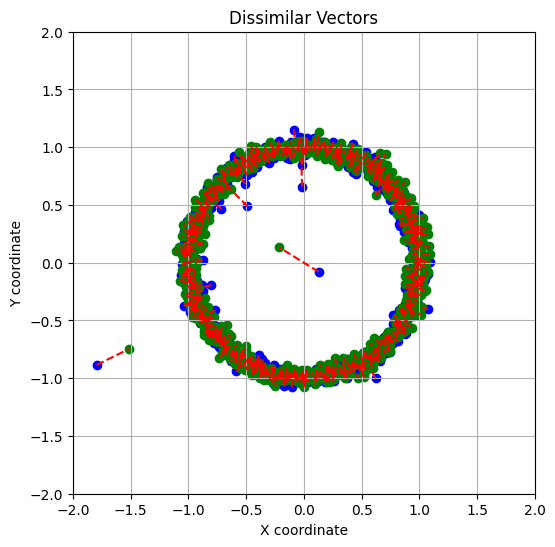

In [93]:
print(concept_raws[index1])
print(concept_raws[index2])
plot_vectors(emb_vec_1, emb_vec_2, "Dissimilar Vectors", show_labels=False, normalize=True)